# What is an outlier?
- An outlier is a data point that is very different from other observations in a dataset.

# Types of Outlier Detection Methods
1. Boxplat method:--> Visualizes extreme values.
2. IQR method:--> Uses quarttiles to identify outliers.
3. Z-score method:-->How far a value is from the standard deviations.
4. Percentile method:--> Identifies values outside percentageile limits.

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [19]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/day38_outlier_detection.csv")

In [20]:
df.head()

,Order_ID,City,Category,Customer_Age,Quantity,Unit_Price_INR,Discount_Percent,Customer_Rating,Revenue_INR,Profit_INR
0,ORD001,Bengaluru,Grocery,40,2,3536,5,4.7,6718.4,1850.85
1,ORD002,Kurnool,Furniture,32,6,19256,0,2.3,115536.0,35007.70
2,ORD003,Bengaluru,Clothing,53,2,12495,10,2.7,22491.0,3996.56
3,ORD004,Kurnool,Clothing,56,2,95000,5,3.8,180500.0,54150.00
4,ORD005,Hyderabad,Clothing,33,2,560,15,4.3,952.0,274.71


In [21]:
df.shape

(60, 10)

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          60 non-null     object 
 1   City              60 non-null     object 
 2   Category          60 non-null     object 
 3   Customer_Age      60 non-null     int64  
 4   Quantity          60 non-null     int64  
 5   Unit_Price_INR    60 non-null     int64  
 6   Discount_Percent  60 non-null     int64  
 7   Customer_Rating   60 non-null     float64
 8   Revenue_INR       60 non-null     float64
 9   Profit_INR        60 non-null     float64
dtypes: float64(3), int64(4), object(3)
memory usage: 4.8+ KB


In [23]:
df.describe()

,Customer_Age,Quantity,Unit_Price_INR,Discount_Percent,Customer_Rating,Revenue_INR,Profit_INR
count,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
mean,41.433333,4.083333,10585.416667,9.666667,3.588333,37781.551667,9134.582833
std,15.567640,3.832473,12625.727431,7.749613,0.926830,43184.255127,12462.664218
min,18.000000,1.000000,403.000000,0.000000,2.100000,952.000000,274.710000
25%,31.750000,2.000000,3752.250000,5.000000,2.700000,9068.175000,1568.110000
50%,39.500000,4.000000,7898.000000,10.000000,3.750000,23494.750000,3983.615000
75%,51.250000,5.000000,15197.250000,15.000000,4.400000,51810.750000,10176.497500
max,110.000000,30.000000,95000.000000,25.000000,5.000000,188413.500000,54150.000000


In [24]:
df.isnull().sum()

Order_ID            0
City                0
Category            0
Customer_Age        0
Quantity            0
Unit_Price_INR      0
Discount_Percent    0
Customer_Rating     0
Revenue_INR         0
Profit_INR          0
dtype: int64

In [25]:
df.duplicated().sum()

np.int64(0)

In [26]:
numeric_df = df.select_dtypes(include="number")
numeric_df.head()

,Customer_Age,Quantity,Unit_Price_INR,Discount_Percent,Customer_Rating,Revenue_INR,Profit_INR
0,40,2,3536,5,4.7,6718.4,1850.85
1,32,6,19256,0,2.3,115536.0,35007.70
2,53,2,12495,10,2.7,22491.0,3996.56
3,56,2,95000,5,3.8,180500.0,54150.00
4,33,2,560,15,4.3,952.0,274.71


In [27]:
numeric_df.describe()

,Customer_Age,Quantity,Unit_Price_INR,Discount_Percent,Customer_Rating,Revenue_INR,Profit_INR
count,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
mean,41.433333,4.083333,10585.416667,9.666667,3.588333,37781.551667,9134.582833
std,15.567640,3.832473,12625.727431,7.749613,0.926830,43184.255127,12462.664218
min,18.000000,1.000000,403.000000,0.000000,2.100000,952.000000,274.710000
25%,31.750000,2.000000,3752.250000,5.000000,2.700000,9068.175000,1568.110000
50%,39.500000,4.000000,7898.000000,10.000000,3.750000,23494.750000,3983.615000
75%,51.250000,5.000000,15197.250000,15.000000,4.400000,51810.750000,10176.497500
max,110.000000,30.000000,95000.000000,25.000000,5.000000,188413.500000,54150.000000


In [28]:
numeric_df.agg(["min", "max"])

,Customer_Age,Quantity,Unit_Price_INR,Discount_Percent,Customer_Rating,Revenue_INR,Profit_INR
min,18,1,403,0,2.1,952.0,274.71
max,110,30,95000,25,5.0,188413.5,54150.00


In [29]:
df["Customer_Age"].sort_values(ascending=False).head(10)

21    110
17     65
22     62
53     62
37     61
38     60
52     56
46     56
3      56
55     55
Name: Customer_Age, dtype: int64

In [30]:
df.nlargest(10, "Revenue_INR")

,Order_ID,City,Category,Customer_Age,Quantity,Unit_Price_INR,Discount_Percent,Customer_Rating,Revenue_INR,Profit_INR
45,ORD046,Chennai,Electronics,35,30,6611,5,4.7,188413.5,47103.38
3,ORD004,Kurnool,Clothing,56,2,95000,5,3.8,180500.0,54150.00
21,ORD022,Chennai,Clothing,110,6,7311,20,4.2,180000.0,54000.00
1,ORD002,Kurnool,Furniture,32,6,19256,0,2.3,115536.0,35007.70
20,ORD021,Kurnool,Grocery,26,6,18926,5,3.7,107878.2,21531.16
36,ORD037,Chennai,Clothing,46,5,19436,0,4.8,97180.0,25904.25
37,ORD038,Chennai,Grocery,61,6,13359,5,2.7,76146.3,25026.29
42,ORD043,Kurnool,Clothing,19,5,18474,25,2.7,69277.5,13165.26
50,ORD051,Hyderabad,Furniture,37,4,19215,10,4.0,69174.0,22137.43
38,ORD039,Kurnool,Electronics,60,5,18344,25,2.1,68790.0,18404.82


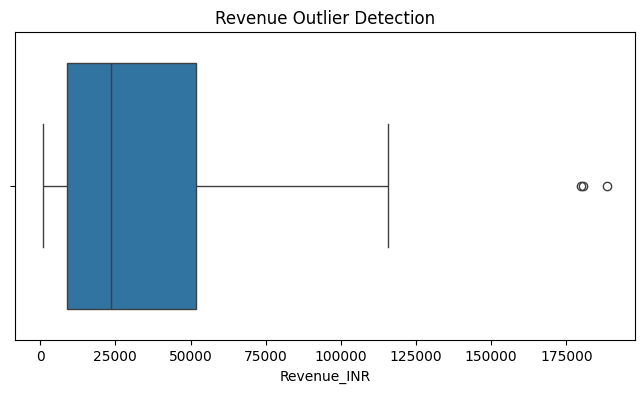

In [31]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["Revenue_INR"])
plt.title("Revenue Outlier Detection")
plt.show()

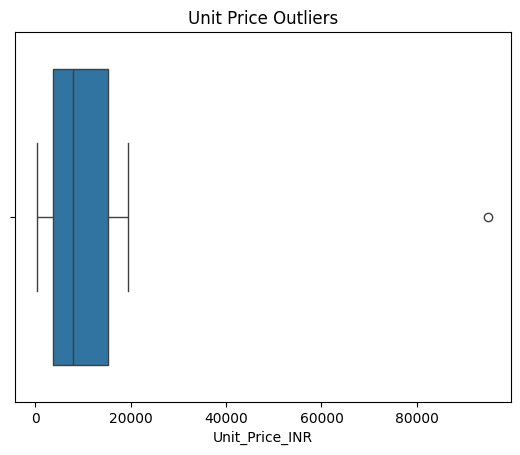

In [32]:
sns.boxplot(x=df["Unit_Price_INR"])
plt.title("Unit Price Outliers")
plt.show()

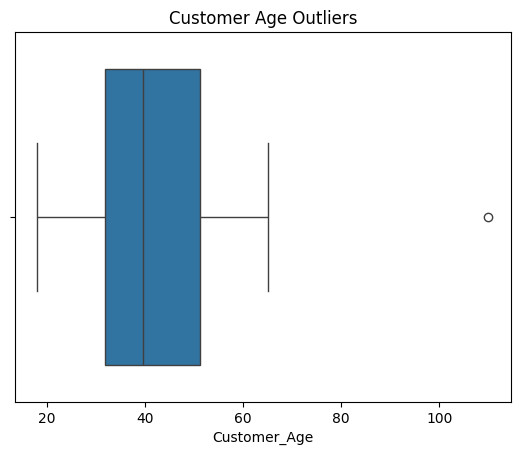

In [33]:
sns.boxplot(x=df["Customer_Age"])
plt.title("Customer Age Outliers")
plt.show()

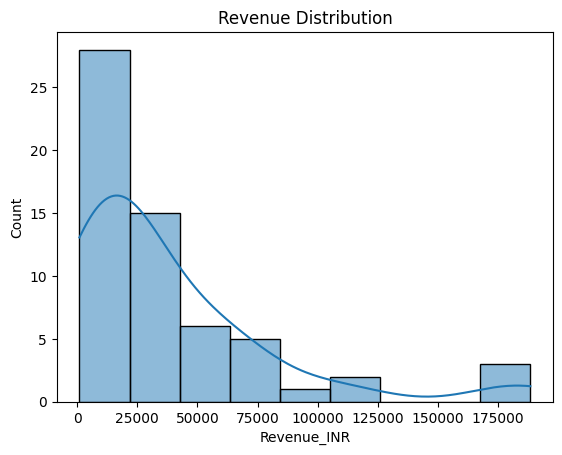

In [34]:
sns.histplot(df["Revenue_INR"], kde=True)
plt.title("Revenue Distribution")
plt.show()

In [35]:
Q1 = df["Revenue_INR"].quantile(0.25)
Q3 = df["Revenue_INR"].quantile(0.75)
print("Q1:", Q1)
print("Q3:", Q3)

Q1: 9068.175
Q3: 51810.75


In [36]:
IQR = Q3 - Q1
print("IQR:", IQR)

IQR: 42742.575


In [37]:
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Lower Limit: -55045.6875
Upper Limit: 115924.61249999999


In [38]:
outliers = df[
    (df["Revenue_INR"] < lower_limit) |
    (df["Revenue_INR"] > upper_limit)]
outliers

,Order_ID,City,Category,Customer_Age,Quantity,Unit_Price_INR,Discount_Percent,Customer_Rating,Revenue_INR,Profit_INR
3,ORD004,Kurnool,Clothing,56,2,95000,5,3.8,180500.0,54150.00
21,ORD022,Chennai,Clothing,110,6,7311,20,4.2,180000.0,54000.00
45,ORD046,Chennai,Electronics,35,30,6611,5,4.7,188413.5,47103.38


In [39]:
len(outliers)

3

In [41]:
normal_data = df[
    (df["Revenue_INR"] >= lower_limit) &
    (df["Revenue_INR"] <= upper_limit)]

normal_data.head()

,Order_ID,City,Category,Customer_Age,Quantity,Unit_Price_INR,Discount_Percent,Customer_Rating,Revenue_INR,Profit_INR
0,ORD001,Bengaluru,Grocery,40,2,3536,5,4.7,6718.4,1850.85
1,ORD002,Kurnool,Furniture,32,6,19256,0,2.3,115536.0,35007.70
2,ORD003,Bengaluru,Clothing,53,2,12495,10,2.7,22491.0,3996.56
4,ORD005,Hyderabad,Clothing,33,2,560,15,4.3,952.0,274.71
5,ORD006,Hyderabad,Furniture,42,3,3588,10,2.7,9687.6,1182.35


In [42]:
from scipy.stats import zscore
df["Revenue_Zscore"] = zscore(df["Revenue_INR"])
df[["Revenue_INR", "Revenue_Zscore"]].head()

,Revenue_INR,Revenue_Zscore
0,6718.4,-0.725387
1,115536.0,1.815722
2,22491.0,-0.357065
3,180500.0,3.332762
4,952.0,-0.860044


In [43]:
zscore_outliers = df[df["Revenue_Zscore"].abs() > 3]
zscore_outliers

,Order_ID,City,Category,Customer_Age,Quantity,Unit_Price_INR,Discount_Percent,Customer_Rating,Revenue_INR,Profit_INR,Revenue_Zscore
3,ORD004,Kurnool,Clothing,56,2,95000,5,3.8,180500.0,54150.00,3.332762
21,ORD022,Chennai,Clothing,110,6,7311,20,4.2,180000.0,54000.00,3.321086
45,ORD046,Chennai,Electronics,35,30,6611,5,4.7,188413.5,47103.38,3.517558


In [44]:
df_without_outliers = df[
    (df["Revenue_INR"] >= lower_limit) &
    (df["Revenue_INR"] <= upper_limit)]

print("Original shape:", df.shape)
print("New shape:", df_without_outliers.shape)

Original shape: (60, 11)
New shape: (57, 11)


In [45]:
df["Revenue_Clipped"] = df["Revenue_INR"].clip(lower=lower_limit,upper=upper_limit)
df[["Revenue_INR", "Revenue_Clipped"]].head()

,Revenue_INR,Revenue_Clipped
0,6718.4,6718.4000
1,115536.0,115536.0000
2,22491.0,22491.0000
3,180500.0,115924.6125
4,952.0,952.0000


Before: 37781.551666666666
After: 34429.22395833333


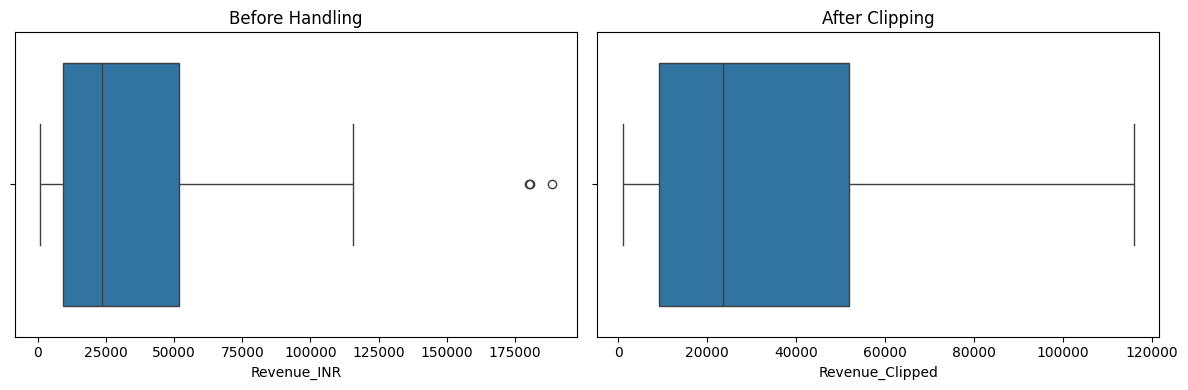

In [46]:
print("Before:", df["Revenue_INR"].mean())
print("After:", df["Revenue_Clipped"].mean())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["Revenue_INR"], ax=axes[0])
axes[0].set_title("Before Handling")
sns.boxplot(x=df["Revenue_Clipped"], ax=axes[1])
axes[1].set_title("After Clipping")
plt.tight_layout()
plt.show()